# Lecture 1: Business Cycle Facts

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johanneswieland/RBC/blob/main/lectures/01_business_cycle_facts.ipynb)

**Economics 210A: Macroeconomics** · Johannes Wieland

Before we build models of the business cycle we need to know what we want them to explain. This lecture
1. separates *trend* from *cycle* using the Hodrick–Prescott (HP) filter,
2. constructs the standard set of U.S. business cycle statistics from public data (FRED and Fernald's TFP database), and
3. summarizes the stylized facts that the real business cycle (RBC) model of the next lectures will try to match.

Every number and figure below is produced by the code in this notebook, so you can rerun it, change the sample or filter, and check how robust the facts are.

## Readings

- King, R. G. and S. T. Rebelo (1999), "[Resuscitating Real Business Cycles](https://doi.org/10.3386/w7534)," *Handbook of Macroeconomics*, Vol. 1B, Ch. 14.
- The great debate in the *Federal Reserve Bank of Minneapolis Quarterly Review*, Fall 1986:
  - Prescott, "[Theory Ahead of Business Cycle Measurement](https://www.minneapolisfed.org/research/quarterly-review/theory-ahead-of-business-cycle-measurement)"
  - Summers, "[Some Skeptical Observations on Real Business Cycle Theory](https://www.minneapolisfed.org/research/quarterly-review/some-skeptical-observations-on-real-business-cycle-theory)"
  - Prescott, "[Response to a Skeptic](https://www.minneapolisfed.org/research/quarterly-review/response-to-a-skeptic)"

## Setup

The helper functions live in [`code/bcdata.py`](../code/bcdata.py). On Colab, the cell below first clones the repository.

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("RBC"):
    !git clone -q https://github.com/johanneswieland/RBC.git
    os.chdir("RBC/lectures")
sys.path.insert(0, os.path.abspath("../code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bcdata
from bcdata import COLORS

bcdata.set_plot_style()
pd.set_option("display.precision", 2)

## 1. Data

All quantities are **real and per capita** (divided by total U.S. population, FRED `B230RC0Q173SBEA`). Output, hours, and capital refer to the U.S. business sector and come from [Fernald's quarterly TFP database](https://www.frbsf.org/research-and-insights/data-and-indicators/total-factor-productivity-tfp/), which carefully constructs consistent series. Everything else comes from [FRED](https://fred.stlouisfed.org).

| Variable | Construction | Source |
|---|---|---|
| GDP $Y$ | business-sector output | Fernald `dY` |
| Hours $N$ | business-sector hours worked | Fernald `dhours` |
| Capital $K$ | business-sector capital input | Fernald `dk` |
| Consumption $C$ | nondurables + services | FRED `A796RX0Q048SBEA`, `A797RX0Q048SBEA` |
| Investment $I$ | gross private domestic investment + consumer durables | FRED `GPDIC1`, `A795RX0Q048SBEA` |
| GDP per hour $Y/N$ | labor productivity | constructed |
| Real wage $W/P$ | real hourly compensation, nonfarm business | FRED `COMPRNFB` |
| Extensive margin | payroll employment / population | FRED `PAYEMS` |
| Intensive margin | hours / employment | constructed |
| Real rate $r$ | 3-month T-bill minus realized GDP-deflator inflation (annualized, p.p.) | FRED `TB3MS`, `GDPDEF` |
| TFP $A$ | Solow residual $\ln Y - \alpha \ln K - (1-\alpha)\ln N$, with $\alpha = 0.35$ | constructed |

Consumer durables are counted as investment rather than consumption: they are long-lived assets that provide a flow of services, which is how the model treats capital.

`load_raw()` downloads the latest vintage and saves a snapshot in `data/`. If the download fails (e.g. offline), it falls back to the snapshot. Pass `use_snapshot=True` to reproduce exactly the numbers in the committed version of this notebook.

In [2]:
# Sample.
# try END = "2019-12-31" or None (latest data) and see what changes.
START, END = "1947-01-01", None

raw = bcdata.load_raw()
levels = bcdata.build_series(raw.loc[START:END])
levels.tail()

Downloaded data: 1947-01-01 to 2026-07-01


,GDP,Hours,Capital,Consumption,Investment,GDP per Hour,Real Wage,Extensive Margin,Intensive Margin,Real Rate,TFP,recession
observation_date,,,,,,,,,,,,
2025-07-01,-10.16,-11.98,-9.93,10.65,9.87,1.82,4.70,-0.77,-11.21,0.78,1.10,0.0
2025-10-01,-10.15,-11.98,-9.93,10.65,9.87,1.83,4.71,-0.77,-11.21,0.34,1.11,0.0
2026-01-01,-10.15,-11.98,-9.92,10.65,9.88,1.83,4.71,-0.77,-11.21,0.45,1.11,0.0
2026-04-01,-10.14,-11.98,-9.91,10.66,9.89,1.83,4.71,-0.77,-11.21,-2.33,1.11,0.0
2026-07-01,-10.13,-11.98,-9.90,10.67,9.93,1.84,4.71,-0.77,-11.21,1.66,1.12,0.0


## 1.1 U.S. real GDP per capita

Start with the most basic picture: real GDP per person (FRED [`A939RX0Q048SBEA`](https://fred.stlouisfed.org/series/A939RX0Q048SBEA), chained 2017 dollars), with NBER recessions shaded. This plot uses all available data, including the COVID-19 recession.

Average growth rate: 1.95% per year;  output per person rose 4.7-fold.


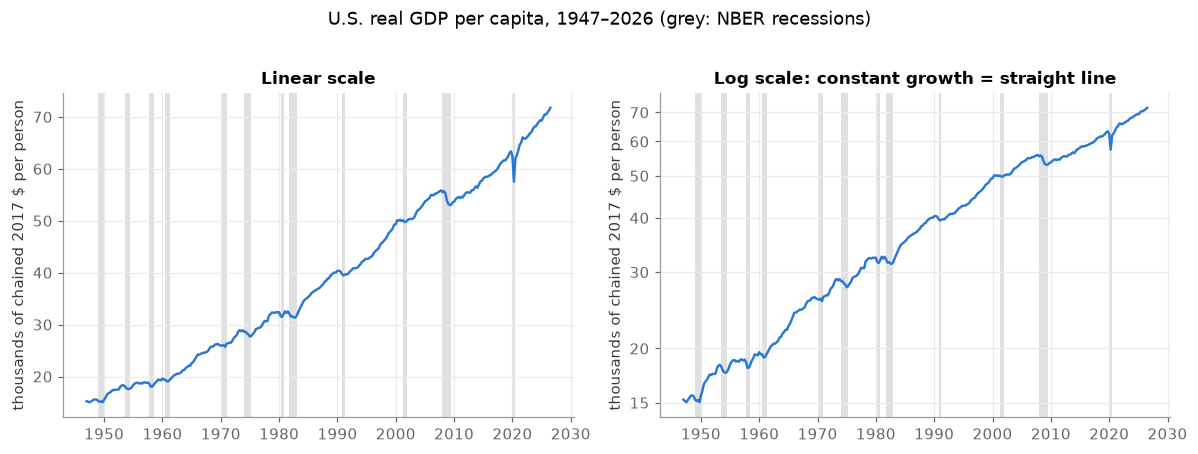

In [3]:
gdp_pc = raw["GDP_pc_nipa"].dropna() / 1000          # thousands of chained 2017 $

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, logscale in zip(axes, [False, True]):
    ax.plot(gdp_pc.index, gdp_pc, color=COLORS["gdp"])
    bcdata.shade_recessions(ax, raw["recession"].loc[gdp_pc.index])
    if logscale:
        ax.set_yscale("log")
        ax.set_yticks([15, 20, 30, 40, 50, 60, 70])
        ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
        ax.set_title("Log scale: constant growth = straight line")
    else:
        ax.set_title("Linear scale")
    ax.set_ylabel("thousands of chained 2017 $ per person")
fig.suptitle(f"U.S. real GDP per capita, {gdp_pc.index[0]:%Y}–{gdp_pc.index[-1]:%Y} (grey: NBER recessions)", y=1.02)
plt.tight_layout()

g = 400 * np.log(gdp_pc).diff().mean()
print(f"Average growth rate: {g:.2f}% per year;  output per person rose {gdp_pc.iloc[-1]/gdp_pc.iloc[0]:.1f}-fold.")

Two things stand out. First, a strong upward **trend**: output per person grows at roughly 2% a year, so it is several times larger than in 1947. On a log scale the trend is close to a straight line. Second, **fluctuations around the trend**: output falls in every recession and then recovers. In the raw level these fluctuations look small next to the trend. To study them we need to separate the two.

### 2. Trend and cycle

The diagram below is a stylized version. We write log output as trend plus cycle,

$$
y_t = \tau_t + c_t .
$$

- A **peak** is a local maximum of output and a **trough** is a local minimum.
- A **recession** (contraction) runs from peak to trough; an **expansion** runs from trough to the next peak. The NBER dates these turning points for the U.S.
- The **cycle** $c_t = y_t - \tau_t$ is output's deviation from trend (bottom panel). It is the object business cycle theory tries to explain.

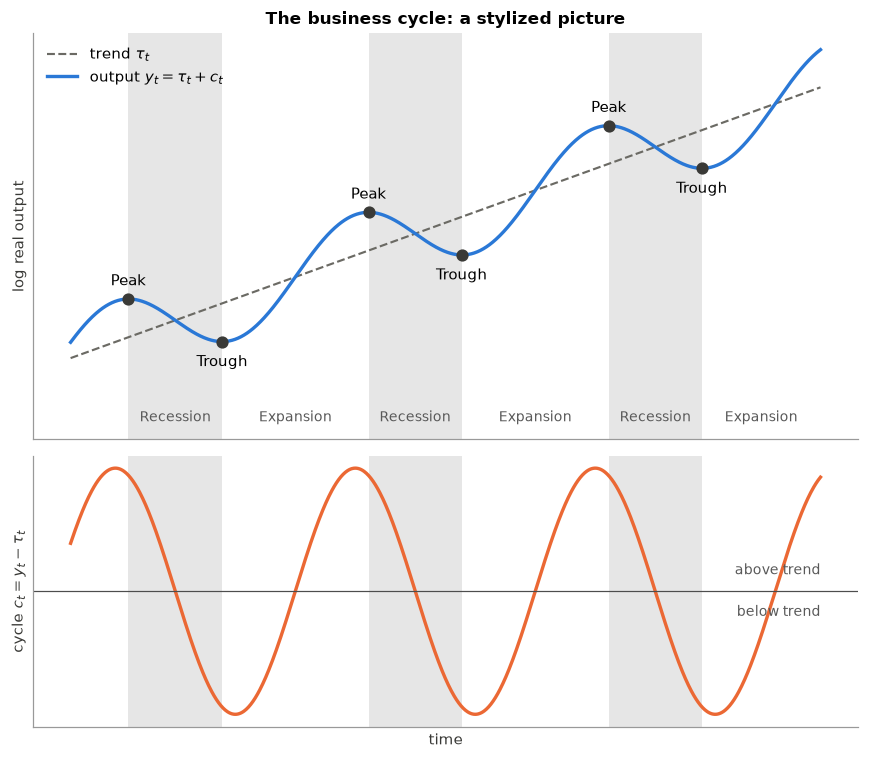

In [4]:
from scipy.signal import argrelextrema

t = np.linspace(0, 10, 1000)
trend = 1.0 + 0.30 * t                                   # tau_t: steady growth
cyc = 0.45 * np.sin(2 * np.pi * t / 3.2 + 0.4)           # c_t: recurring fluctuations
y = trend + cyc                                          # y_t = tau_t + c_t

peaks = argrelextrema(y, np.greater)[0]
troughs = argrelextrema(y, np.less)[0]

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

ax = axes[0]
ax.plot(t, trend, color=COLORS["trend"], ls="--", lw=1.4, label=r"trend $\tau_t$")
ax.plot(t, y, color=COLORS["gdp"], lw=2.2, label=r"output $y_t = \tau_t + c_t$")
for p in peaks:
    tr = troughs[troughs > p]
    end = tr[0] if len(tr) else len(t) - 1
    for a in axes:
        a.axvspan(t[p], t[end], color="0.9", lw=0, zorder=0)
    ax.text((t[p] + t[end]) / 2, 0.3, "Recession", ha="center", fontsize=9, color="0.35")
for i, tr in enumerate(troughs):
    nxt = peaks[peaks > tr]
    end = nxt[0] if len(nxt) else len(t) - 1
    ax.text((t[tr] + t[end]) / 2, 0.3, "Expansion", ha="center", fontsize=9, color="0.35")
ax.plot(t[peaks], y[peaks], "o", color=COLORS["text"], ms=7)
ax.plot(t[troughs], y[troughs], "o", color=COLORS["text"], ms=7)
for p in peaks:
    ax.annotate("Peak", (t[p], y[p]), xytext=(0, 9), textcoords="offset points", ha="center")
for tr in troughs:
    ax.annotate("Trough", (t[tr], y[tr]), xytext=(0, -16), textcoords="offset points", ha="center")
ax.set_ylim(0.1, 4.6)
ax.set_ylabel("log real output")
ax.set_title("The business cycle: a stylized picture")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(t, cyc, color=COLORS["series"], lw=2.2)
ax.axhline(0, color="0.3", lw=0.8)
ax.text(t[-1], 0.05, "above trend", ha="right", va="bottom", fontsize=9, color="0.35")
ax.text(t[-1], -0.05, "below trend", ha="right", va="top", fontsize=9, color="0.35")
ax.set_ylabel(r"cycle $c_t = y_t - \tau_t$")
ax.set_xlabel("time")
for a in axes:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

## 2.1 The HP filter

We need a way to split a (log) series $y_t$ into a trend $\tau_t$ and a cycle $c_t = y_t - \tau_t$.

[Hodrick and Prescott (1997)](https://doi.org/10.2307/2953682) define the trend as the solution to

$$
\min_{\{\tau_t\}_{t=1}^T} \; \sum_{t=1}^{T} (y_t - \tau_t)^2 \;+\; \lambda \sum_{t=2}^{T-1} \big[(\tau_{t+1}-\tau_t) - (\tau_t - \tau_{t-1})\big]^2 .
$$

The first term rewards fitting the data; the second penalizes changes in the trend's *growth rate*. The smoothing parameter $\lambda$ governs the trade-off:
- $\lambda = 0$: $\tau_t = y_t$ (no cycle at all);
- $\lambda \to \infty$: $\tau_t$ becomes a linear time trend.

For quarterly data the convention is $\lambda = 1600$, which roughly removes fluctuations with periods longer than 8 years (32 quarters).

**The HP filter is just least squares.** Stack $y = (y_1,\dots,y_T)'$ and let $D$ be the $(T-2)\times T$ second-difference matrix with rows $(\dots, 1, -2, 1, \dots)$. The objective is $(y-\tau)'(y-\tau) + \lambda\, \tau' D'D\, \tau$, and the first-order condition gives

$$
\tau = (I + \lambda D'D)^{-1} y .
$$

Let's implement this in a few lines and check it against `statsmodels`.

In [5]:
def hp_filter(y, lam=1600):
    # HP trend by solving (I + lam D'D) tau = y
    T = len(y)
    D = np.zeros((T - 2, T))
    for t in range(T - 2):
        D[t, t:t + 3] = [1, -2, 1]
    tau = np.linalg.solve(np.eye(T) + lam * D.T @ D, y)
    return y - tau, tau          # (cycle, trend)

y = levels["GDP"].values
cycle_ours, trend_ours = hp_filter(y)
cycles, trends = bcdata.hp_cycles(levels)          # statsmodels, all series

print("max |difference| vs statsmodels:", np.abs(100 * cycle_ours - cycles["GDP"].values).max())

max |difference| vs statsmodels: 3.8475889141409425e-10


Below we implement the HP filter for log GDP. Grey bars are NBER recessions. Every recession shows up as a large negative deviation from trend.

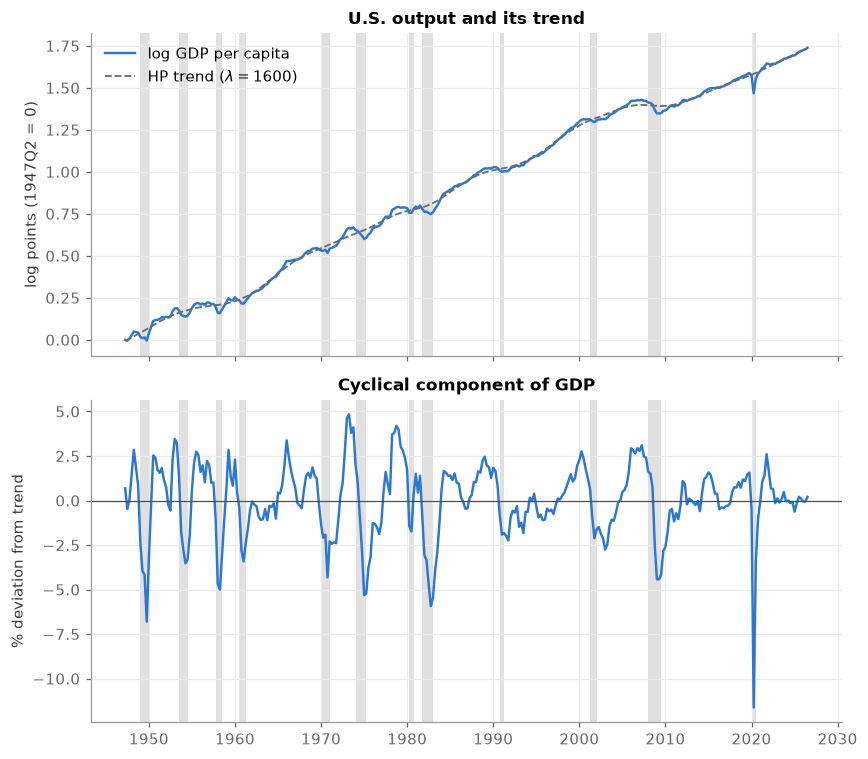

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax = axes[0]
y0 = levels["GDP"].iloc[0]   # normalize so that log GDP = 0 in the first quarter
ax.plot(levels.index, levels["GDP"] - y0, color=COLORS["gdp"], label="log GDP per capita")
ax.plot(trends.index, trends["GDP"] - y0, color=COLORS["trend"], ls="--", lw=1.2, label="HP trend ($\\lambda=1600$)")
bcdata.shade_recessions(ax, levels["recession"])
ax.set_title("U.S. output and its trend")
ax.set_ylabel("log points (1947Q2 = 0)")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(cycles.index, cycles["GDP"], color=COLORS["gdp"])
ax.axhline(0, color="0.3", lw=0.8)
bcdata.shade_recessions(ax, levels["recession"])
ax.set_title("Cyclical component of GDP")
ax.set_ylabel("% deviation from trend")
plt.tight_layout()

**Caveats.** The HP filter is a statistical procedure, and may be incompatible with the underlying economics of your model.

- See [Hamilton (2018), "Why You Should Never Use the Hodrick-Prescott Filter,"](https://doi.org/10.1162/rest_a_00706) *Review of Economics and Statistics* 100(5) ([NBER WP 23429](https://www.nber.org/papers/w23429)) for a critique.
- There are many different filters out there. In practice, you either want to show that the filtering choice does not matter or you have a convincing reason to prefer one filter over another.
- [Donaldson and Wieland, "Why Are Some Recoveries Weak and Others Strong?"](https://johanneswieland.github.io/Papers/Recoveries_Donaldson_Wieland.pdf) argue that cross-sectional estimates can be much more robust to filtering errors.

## 3. The business cycle facts

For each HP-filtered series $x_t$ we report:
- the standard deviation $\sigma_x$ (in %, or p.p. for the real rate),
- volatility relative to output, $\sigma_x / \sigma_Y$,
- the contemporaneous correlation with output, $\rho(x_t, Y_t)$, which measures *cyclicality*,
- the first-order autocorrelation $\rho(x_t, x_{t-1})$, which measures *persistence*.

In [7]:
order = ["GDP", "Consumption", "Investment", "Hours", "Extensive Margin", "Intensive Margin",
         "GDP per Hour", "Real Wage", "Capital", "Real Rate", "TFP"]
facts = bcdata.bc_moments(cycles).loc[order]
facts

,SD (%),SD / SD(GDP),"Corr(x, GDP)","Corr(x_t, x_t-1)"
GDP,2.07,1.00,1.00,0.80
Consumption,1.06,0.51,0.76,0.68
Investment,6.30,3.05,0.88,0.80
Hours,2.01,0.97,0.86,0.81
Extensive Margin,1.59,0.77,0.78,0.82
Intensive Margin,0.76,0.37,0.64,0.80
GDP per Hour,1.07,0.51,0.32,0.75
Real Wage,1.16,0.56,0.02,0.73
Capital,0.54,0.26,-0.12,0.96
Real Rate,1.77,0.85,-0.02,0.50


### What the table says (1947–2025)

1. **Consumption is smooth.** It is half as volatile as output and strongly procyclical.
2. **Investment is very volatile.** It is about three times as volatile as output and strongly procyclical.
3. **Hours are about as volatile as output** and strongly procyclical. Most of the variation comes from the extensive margin (employment), not hours per worker.
4. **Labor productivity and real wages are only mildly procyclical** and much less volatile than hours. Any model in which hours move along a stable labor supply curve has to explain how large swings in hours coexist with small, weakly procyclical wage movements. This will be a central challenge for the RBC model.
5. **The capital stock is smooth, very persistent, and acyclical.** It is a slow-moving state variable.
6. **The real interest rate is essentially acyclical.**
7. **Measured TFP is volatile, persistent, and strongly procyclical.** This is the observation that motivates technology shocks as the driving force in the RBC model ([Kydland and Prescott, 1982](https://www.jstor.org/stable/1913386)), and also the observation Summers attacks: is the Solow residual really exogenous technology?
8. **Everything is persistent.** Autocorrelations are around 0.8 for most series.

Robert Lucas ([1977, "Understanding Business Cycles"](https://doi.org/10.1016/0167-2231%2877%2990002-1)): "with respect to the qualitative behavior of co-movements among series, business cycles are all alike." The comovements above are remarkably stable across episodes.

## 4. Each series over the cycle

Each panel plots the cyclical component of a series (orange) against that of GDP (blue).

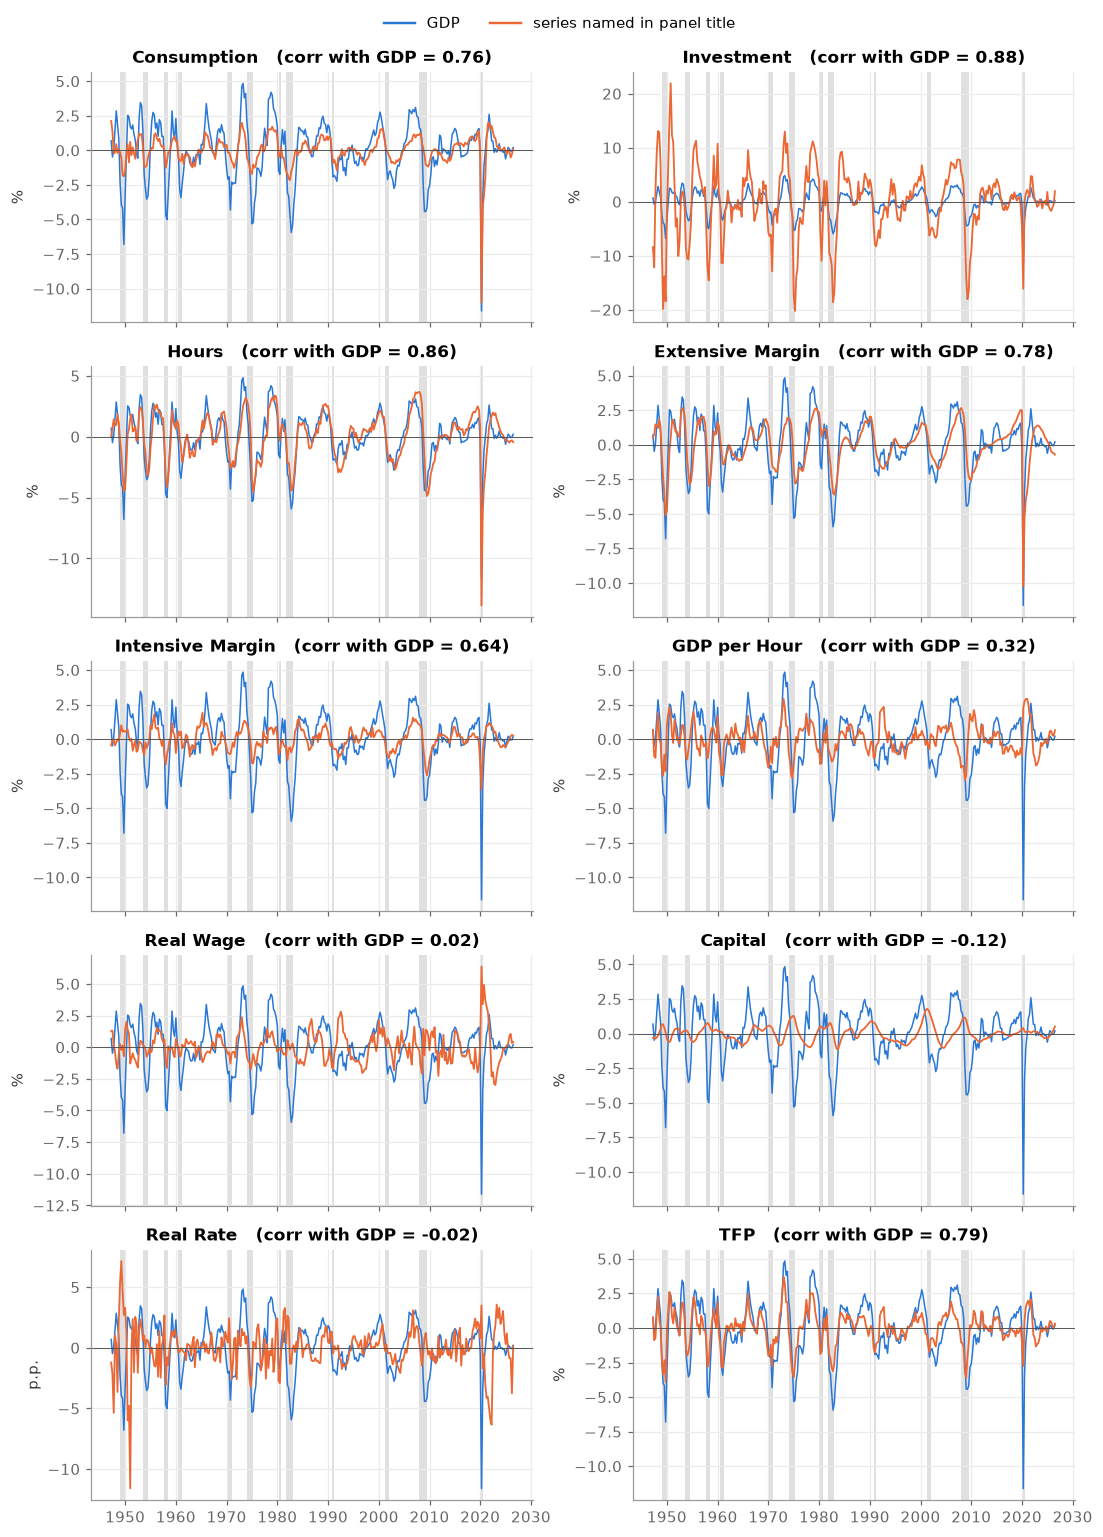

In [8]:
panels = order[1:]
fig, axes = plt.subplots(5, 2, figsize=(10, 14), sharex=True)
for ax, var in zip(axes.flat, panels):
    ax.plot(cycles.index, cycles["GDP"], color=COLORS["gdp"], lw=1.0)
    ax.plot(cycles.index, cycles[var], color=COLORS["series"], lw=1.2)
    ax.axhline(0, color="0.3", lw=0.6)
    bcdata.shade_recessions(ax, levels["recession"])
    unit = "p.p." if var in bcdata.LEVEL_SERIES else "%"
    ax.set_title(f"{var}   (corr with GDP = {facts.loc[var, 'Corr(x, GDP)']:.2f})")
    ax.set_ylabel(unit)
handles = [plt.Line2D([], [], color=COLORS["gdp"]), plt.Line2D([], [], color=COLORS["series"])]
fig.legend(handles, ["GDP", "series named in panel title"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.98))

## 5. How does the economy respond to TFP shocks? Local projections

The moments in Section 3 are unconditional. Conditional moments *condition* on a particular shock or event. Here we treat the cyclical component of the Solow residual, the HP-filtered log TFP from Section 2, as a shock,

$$
\varepsilon_t = c^A_t = 100\,(\ln A_t - \tau^A_t) ,
$$

and trace out how each variable responds over the following quarters using **local projections** ([Jordà, 2005](https://doi.org/10.1257/0002828053828518)). For each horizon $h = 0, 1, \dots, H$ we run a separate regression

$$
y_{t+h} = \alpha_h + \beta_h\, \varepsilon_t + \sum_{j=1}^{p} \gamma_{h,j}\, \varepsilon_{t-j} + \sum_{j=1}^{p} \delta_{h,j}\, y_{t-j} + u_{t+h},
$$

with $p = 4$ lags of both the shock and the dependent variable as a baseline. The sequence $\{\beta_h\}_{h=0}^{H}$ is the impulse response function (IRF): the change in $y$ $h$ quarters after TFP rises 1% above its trend. The estimated IRF is a conditional moment because it shows an estimate of how the economy responds to a particular shock.

The dependent variable $y_t$ is the HP-filtered cycle $c_t$ from Section 2 (in %, or p.p. for the real rate), so the responses describe deviations from the HP trend. By construction the filtered series must revert to zero, so any permanent effect of the shock is removed. And because the filter is two-sided, both $c_t$ and the shock $c^A_t$ depend on future data. The TFP cycle is persistent (its autocorrelation is about 0.8), so the lags of $\varepsilon_t$ in the regression matter: holding $\varepsilon_{t-1},\dots,\varepsilon_{t-4}$ fixed, $\beta_h$ measures the effect of a movement in TFP relative to trend that is not predicted by its own past or the past of $y$. Standard errors are Newey–West (HAC) with $h+1$ lags, because the overlapping horizons make the residuals $u_{t+h}$ serially correlated. Shaded areas are 95% confidence bands.

In [9]:
import statsmodels.api as sm
from scipy.stats import norm

H = 20                 # horizons 0..H quarters
LAGS = 4               # lags of the shock and of the dependent variable
CONF = 0.95            # confidence level for the bands
SPECS = ["HP-filtered"] # add "Log levels" to run the regressions in levels too (exercise 7)

lp_vars = ["GDP", "Investment", "Consumption", "Hours", "Real Wage", "Real Rate"]

# Shock in each specification: HP cycle of log TFP, or 100 x log TFP
shocks = {
    "HP-filtered": cycles["TFP"],
    "Log levels":  100 * levels["TFP"],
}

# Dependent variable in each specification (same units: % or p.p.)
data = {
    "Log levels":  pd.DataFrame({v: levels[v] * (1 if v in bcdata.LEVEL_SERIES else 100) for v in lp_vars}),
    "HP-filtered": cycles[lp_vars],
}


def local_projection(y, shock, H=20, lags=4, conf=0.95):
    # IRF of y to shock: for each h, regress y_{t+h} on shock_t, `lags` lags of shock and of y
    X = pd.concat({"shock": shock,
                   **{f"shock_l{j}": shock.shift(j) for j in range(1, lags + 1)},
                   **{f"y_l{j}": y.shift(j) for j in range(1, lags + 1)}}, axis=1)
    X = sm.add_constant(X)
    z = norm.ppf(0.5 + conf / 2)
    rows = []
    for h in range(H + 1):
        d = pd.concat([y.shift(-h).rename("lhs"), X], axis=1).dropna()
        res = sm.OLS(d["lhs"], d.drop(columns="lhs")).fit(cov_type="HAC", cov_kwds={"maxlags": h + 1})
        b, se = res.params["shock"], res.bse["shock"]
        rows.append({"h": h, "irf": b, "lo": b - z * se, "hi": b + z * se, "nobs": int(res.nobs)})
    return pd.DataFrame(rows).set_index("h")


irfs = {(spec, v): local_projection(data[spec][v], shocks[spec], H, LAGS, CONF) for spec in SPECS for v in lp_vars}
s = shocks["HP-filtered"]
print(f"Shock: HP-filtered log TFP, sd = {s.std():.2f}%, autocorrelation = {s.autocorr():.2f};  "
      f"sample {levels.index[0]:%Y}-{levels.index[-1]:%Y}")

Shock: HP-filtered log TFP, sd = 1.22%, autocorrelation = 0.78;  sample 1947-2026


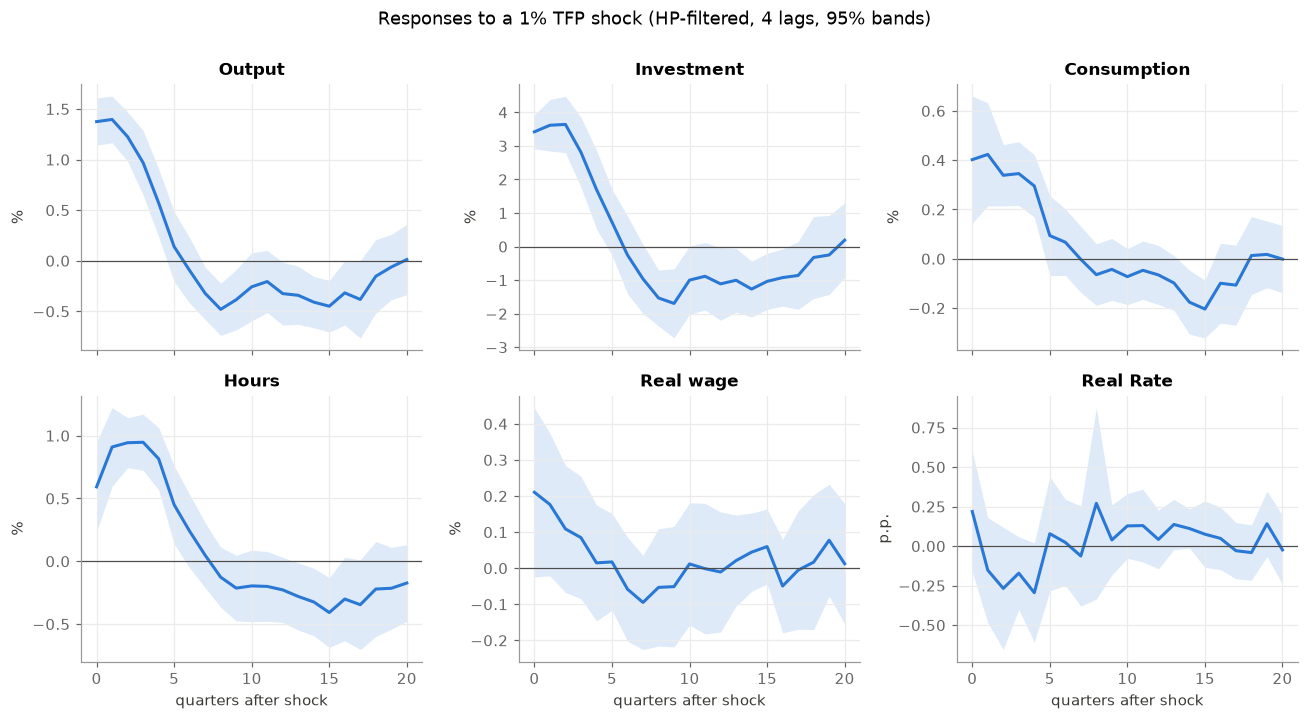

In [10]:
spec_color = {"HP-filtered": COLORS["gdp"], "Log levels": COLORS["series"]}
titles = {"GDP": "Output", "Real Wage": "Real wage"}

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True)
for ax, v in zip(axes.flat, lp_vars):
    for spec in SPECS:
        col = spec_color[spec]
        r = irfs[(spec, v)]
        ax.fill_between(r.index, r["lo"], r["hi"], color=col, alpha=0.15, lw=0)
        ax.plot(r.index, r["irf"], color=col, lw=2, label=spec)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(titles.get(v, v))
    ax.set_ylabel("p.p." if v in bcdata.LEVEL_SERIES else "%")
for ax in axes[1]:
    ax.set_xlabel("quarters after shock")
if len(SPECS) > 1:
    handles = [plt.Line2D([], [], color=spec_color[s], lw=2) for s in SPECS]
    fig.legend(handles, SPECS, loc="upper center", ncol=len(SPECS), bbox_to_anchor=(0.5, 1.02))
fig.suptitle(f"Responses to a 1% TFP shock ({', '.join(SPECS)}, {LAGS} lags, {int(CONF*100)}% bands)",
             y=1.07 if len(SPECS) > 1 else 1.0)
plt.tight_layout()

**What the responses show (full sample).**

1. **Everything comoves.** After a positive Solow-residual shock, output, investment, consumption, and hours all rise on impact. Investment rises by two to three times as much as output and consumption by much less, the same ranking as in the volatility table. Measured TFP shocks reproduce the unconditional business cycle facts.
2. **Hours rise and the real wage barely moves.** Again, similar to the unconditional moments.
3. **The effects are temporary relative to trend.** The responses peak within the first year, cross zero after about six quarters, and then stay somewhat below trend for several years. Part of this is mechanical: the HP filter assigns any permanent effect of the shock to the trend. It can also induce a cycle in the filtered variable when none exist (Cogley-Nason).
4. **The real rate** rises briefly on impact and then falls; the response is small and imprecisely estimated.


**Is the Solow residual really a technology shock?** Not necessarily. Firms vary how intensively they use capital and labor over the cycle, so measured TFP can rise in booms even without any change in technology. This was one of Summers' critiques, and [Basu, Fernald, and Kimball (2006)](https://doi.org/10.1257/aer.96.5.1418) pursue it in detail. In this case, the conditional impulse response function we estimate reflect reverse causality.

## 6. Try it yourself

1. **COVID.** Set `END = "2019-12-31"` and rerun. Which moments change most? Why does a single episode matter so much for second moments?
2. **Smoothing.** Recompute the table with `bcdata.hp_cycles(levels, lam=10)` and `lam=100000`. Which facts are robust?
3. **First differences.** Replace the HP cycle by $100\,\Delta \ln x_t$. Do relative volatilities and correlations survive?
4. **Subsamples.** Compare 1947–1983 with 1984–2019 (the *Great Moderation*). What happens to $\sigma_Y$? To the correlation of productivity with output?
5. **Endpoints.** Set `END = "2020-06-30"`, then compare the HP trend in 2019/2020 using data through 2020 vs. through today. How much does the estimated 2019 cycle change?
6. **Hamilton filter.** Implement Hamilton's alternative: regress $y_{t+8}$ on a constant and $y_t,\dots,y_{t-3}$ and take the residual as the cycle. Recompute the facts table. Which facts survive?
7. **Local projections in levels.** Set `SPECS = ["HP-filtered", "Log levels"]` to rerun the regressions in log levels on both sides: the dependent variable is $y_t = 100 \ln Y_t$ (the real rate in p.p.) and the shock is $\varepsilon_t = 100 \ln A_t$, with 4 lags of both. This is a lag-augmented local projection: holding the lags fixed, $\beta_h$ is the response to the innovation in log TFP, the part of $\ln A_t$ not predicted by past TFP and past $y$. [Montiel Olea and Plagborg-Møller (2021)](https://doi.org/10.3982/ECTA18756) show that inference in such regressions remains valid even when the data are highly persistent or have unit roots, provided the data follow a VAR with no more than 4 lags and $h$ is small relative to the sample. Their result concerns inference, not identification: interpreting $\beta_h$ as the effect of a technology shock still requires that the TFP innovation does not respond to $y$ within the quarter, which the utilization critique above questions. The responses are cumulative. Do the two specifications agree on impact? At long horizons? Does the shock have a permanent effect on output, investment, and consumption? What does that imply about the HP-filtered responses? Then add `"TFP"` to `lp_vars`: is the Solow residual close to a random walk?


## Summary and the big questions

**Stylized facts.**
1. Business cycles are recurrent but not periodic: there is no simple regular cycle.
2. Most macro aggregates comove with output.
3. Volatility is spread very unevenly: consumption is smooth, investment is volatile, and hours are about as volatile as output.
4. Productivity and real wages are only weakly procyclical; the real rate is acyclical.
5. Measured TFP is highly procyclical and persistent.

**Big questions.**
1. What shocks cause business cycles?
2. What mechanisms propagate and amplify those shocks?
3. How do business cycles relate to long-run growth?
4. What do business cycles cost, and what can policy do about them?

**Next lecture.** We build the simplest model that could possibly generate these patterns: a frictionless economy hit by technology shocks (the RBC model). We set it up in continuous time and analyze it with a phase diagram.